In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from keras.models import Sequential
from keras.layers import Bidirectional, LSTM, Dense
import math

In [2]:
# 1. Excel dosyasını oku
df = pd.read_excel("veriss.xlsx")

In [3]:
# 2. Tarih formatını düzelt
df['Profil Tarihi'] = pd.to_datetime(df['Profil Tarihi'], dayfirst=True)

In [4]:
# 3. Tarihe göre sırala
df = df.sort_values('Profil Tarihi').reset_index(drop=True)

In [5]:
# 4. Tahmin edilecek sütunu seç (örn. 'Üretim')
target_col = 'Üretim (Veriş)'
data = df[[target_col]].values

In [6]:
# 5. Normalizasyon (0-1 arası)
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(data)

In [7]:
# 6. Zaman serisi yapısı için giriş-çıkış dizilerini oluştur
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(seq_length, len(data)):
        X.append(data[i-seq_length:i])
        y.append(data[i])
    return np.array(X), np.array(y)

sequence_length = 24
X, y = create_sequences(data_scaled, sequence_length)

In [8]:
# 7. Eğitim ve test veri setlerine ayır
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

In [9]:
# 8. BiLSTM Modeli
model = Sequential()
model.add(Bidirectional(LSTM(64, return_sequences=False), input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [10]:
# 9. Modeli eğit
model.fit(X_train, y_train, epochs=20, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - loss: 0.0227 - val_loss: 0.0033
Epoch 2/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - loss: 0.0043 - val_loss: 0.0034
Epoch 3/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - loss: 0.0043 - val_loss: 0.0035
Epoch 4/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - loss: 0.0038 - val_loss: 0.0034
Epoch 5/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - loss: 0.0037 - val_loss: 0.0033
Epoch 6/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - loss: 0.0034 - val_loss: 0.0032
Epoch 7/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - loss: 0.0032 - val_loss: 0.0031
Epoch 8/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - loss: 0.0031 - val_loss: 0.0031
Epoch 9/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - loss: 0.0031 - val_loss: 0.0030
Epoch 10/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - loss: 0.0029 - val_loss: 0.0031
Epoch 11/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - loss: 0.0029 - val_loss: 0.0031
Epoch 12/20
395/395 ━━━━━━━━━━

In [11]:
# 10. Tahmin yap
y_pred_scaled = model.predict(X_test)
y_pred = scaler.inverse_transform(y_pred_scaled)
y_test_real = scaler.inverse_transform(y_test)

219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


In [12]:
# 11. Performans metrikleri
mae = mean_absolute_error(y_test_real, y_pred)
mse = mean_squared_error(y_test_real, y_pred)
rmse = math.sqrt(mse)
r2 = r2_score(y_test_real, y_pred)

In [13]:
# MAPE için sıfır bölme hatasından kaçın
nonzero_mask = y_test_real.flatten() != 0
mape = np.mean(np.abs((y_test_real[nonzero_mask] - y_pred[nonzero_mask]) / y_test_real[nonzero_mask])) * 100

In [14]:
# 12. Metrikleri yazdır
print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")
print(f"MAPE: {mape:.2f}%")

MAE:  11.16
MSE:  513.76
RMSE: 22.67
R²:   0.9690
MAPE: 25.85%


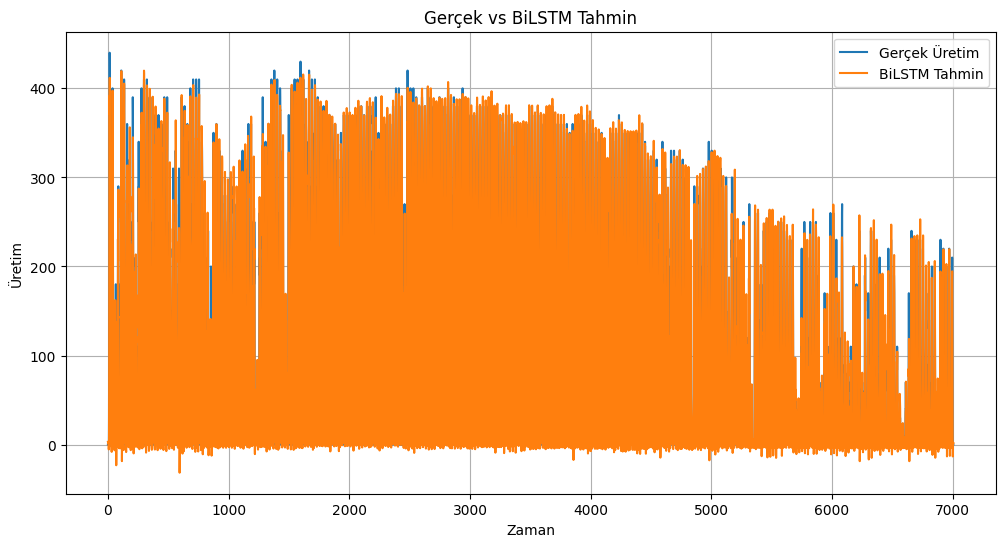

In [15]:
# 13. Tahmin grafiği
plt.figure(figsize=(12,6))
plt.plot(y_test_real, label='Gerçek Üretim')
plt.plot(y_pred, label='BiLSTM Tahmin')
plt.title("Gerçek vs BiLSTM Tahmin")
plt.xlabel("Zaman")
plt.ylabel("Üretim")
plt.legend()
plt.grid(True)
plt.show()